# Projet : simulation de la Ligue des champions

**Question.** Quelles sont les chances de chaque club de gagner la Ligue des champions (ou d'aller en huitièmes, en quarts, etc.) ?

**Méthode.** On simule toute la compétition (phase de ligue + phase finale) 10 000 fois sur ordinateur, avec des scores tirés au hasard. Ensuite on compte : si un club gagne dans 2 000 simulations sur 10 000, on dit qu'il a 20 % de chances de gagner. C'est la méthode de Monte-Carlo.

**Ce qu'il faut retenir**

- Arsenal est le favori avec environ 22 % de chances, devant le Bayern (18,6 %), le Real Madrid (13 %) et le PSG (10 %). À eux quatre, ils gagnent environ 64 % des simulations.
- Même le favori gagne moins d'une fois sur 4 : il y a beaucoup de hasard.
- Le choix du modèle de scores, ou du nombre de buts $\mu$, change peu les résultats (environ 2 points au maximum).
- 10 000 simulations donnent une précision d'environ ±0,8 point pour un club à 20 %. C'est assez pour classer les favoris, pas pour départager deux clubs très proches.
- Ce sont les résultats d'un modèle simple, pas des prévisions : voir les limites en conclusion.

**Plan :** 1. Charger le projet · 2. Les données · 3. Tirer les scores · 4. Une simulation · 5. Résultats · 6. Comparer les modèles · 7. Changer $\mu$ · 8. Combien de simulations · 9. Conclusion

### Comment lancer le notebook

1. Installer Julia (version 1.10 ou plus récente) puis le kernel Jupyter (une seule fois) : `using Pkg; Pkg.add("IJulia")`
2. Ouvrir le notebook avec le kernel Julia
3. Faire **Run All**

Les résultats sont déjà dans le notebook, donc on peut aussi juste le lire.

### Comment ça marche

Pas besoin d'avoir notre dossier, ni git : la première cellule récupère tout toute seule.

- `Pkg.activate(temp = true)` crée un environnement temporaire. Ce qu'on installe dedans ne touche pas aux paquets déjà installés, et disparaît quand on ferme Julia.
- `Pkg.add(url = ..., rev = ...)` télécharge notre projet depuis GitHub (Julia a son propre git intégré, il faut juste Internet), avec ses données et ses dépendances.
- `rev` est le numéro d'un commit précis : on récupère exactement la version du code qui a servi pour ce compte rendu, même si le projet a changé depuis.
- `Pkg.add(["DataFrames", "GLMakie"])` ajoute les paquets pour les tableaux et les graphiques.

La première fois c'est un peu long (une dizaine de minutes pour tout télécharger et compiler), après ça prend environ 3 minutes.

## 1. On charge le projet

`N` est le nombre de simulations utilisé partout (10 000), sauf quand on le fait varier exprès (section 8).

In [1]:
using Pkg
Pkg.activate(temp = true) # environnement temporaire
Pkg.add(url = "https://github.com/Akashii-touc/SimulationsProjet.jl", rev = "d4b39eb19b68b89a6a6fe949cd9ebc425cadba0d") # version figée du projet
Pkg.add(["DataFrames", "GLMakie"])

using SimulationsProjet, DataFrames, GLMakie
GLMakie.activate!(inline = true) # graphiques dans le notebook

N = 10000 # nombre de simulations

  Activating new project at `/var/folders/n3/63rm71kj03s998_zmrlm8dwh0000gn/T/jl_9bmayz`
   Resolving package versions...
    Updating `/private/var/folders/n3/63rm71kj03s998_zmrlm8dwh0000gn/T/jl_9bmayz/Project.toml`
  [1c7c81b7] + SimulationsProjet v0.0.1 `https://github.com/Akashii-touc/SimulationsProjet.jl#d4b39eb`
    Updating `/private/var/folders/n3/63rm71kj03s998_zmrlm8dwh0000gn/T/jl_9bmayz/Manifest.toml`
  [621f4979] + AbstractFFTs v1.5.0
  [1520ce14] + AbstractTrees v0.4.5
  [7d9f7c33] + Accessors v0.1.46
  [79e6a3ab] + Adapt v4.8.0
  [4f381ef7] + AdaptiveArrayPools v0.3.12
  [35492f91] + AdaptivePredicates v1.2.0
  [66dad0bd] + AliasTables v1.1.3
  [27a7e980] + Animations v0.4.2
  [67c07d97] + Automa v1.2.0
  [13072b0f] + AxisAlgorithms v1.1.0
  [39de3d68] + AxisArrays v0.4.8
  [18cc8868] + BaseDirs v1.4.0
⌅ [fa961155] + CEnum v0.5.0
  [96374032] + CRlibm v1.2.0
  [336ed68f] + CSV v1.3.0
  [d360d2e6] + ChainRulesCore v1.26.8
  [da1fd8a2] + CodeTracking v3.0.2
  [944b1d66] + C

10000

## 2. Les données

On a récupéré trois fichiers :
- `classement_club.csv` : pour chacun des 36 clubs, le coefficient UEFA du club, celui de son pays, et son classement Elo. Dans ce compte rendu, on utilise seulement les coefficients UEFA (le projet sait aussi utiliser l'Elo, voir la conclusion)
- `matchs.csv` : le calendrier des 8 journées de la phase de ligue (une colonne = une journée de 18 matchs ; « A - B » veut dire que A reçoit B)
- `tirs_au_but.csv` : les séances de tirs au but de chaque club, avec le nombre de tirs tentés et réussis

In [2]:
first(CLASSEMENT, 10)

Row,Club,Pays,Coeff_club,Coeff_pays,Elo
,String,String,Float64,Float64,Int64
1,Bayern,Allemagne,129.5,81.545,2046
2,Arsenal,Angleterre,127.0,103.796,2040
3,RealMadrid,Espagne,122.5,83.243,1972
4,ParisSG,France,121.0,69.153,1956
5,Inter,Italie,115.0,88.589,1946
6,ManCity,Angleterre,106.5,103.796,2028
7,Barcelone,Espagne,106.25,83.243,2024
8,Liverpool,Angleterre,105.0,103.796,1937
9,Dortmund,Allemagne,98.75,81.545,1900


In [3]:
first(CALENDRIER, 5)

Row,Match_1,Match_2,Match_3,Match 4,Match_5,Match_6,Match_7,Match_8
,String,String,String,String,String,String,String,String
1,Brugge - AstonVilla,Lens - Sporting,Fenerbahçe - SlaviaPrague,Shakhtar - Sporting,Bodo/Glimt - LASK,Villarreal - SabahFC,Bodo/Glimt - AtléticoMadrid,ParisSG - Galatasaray
2,AEKAthènes - LASK,SabahFC - SlaviaPrague,SabahFC - Dortmund,Galatasaray - Stuttgart,Galatasaray - AstonVilla,Viking - Feyenoord,Galatasaray - Feyenoord,Bayern - Betis
3,RealMadrid - Inter,Inter - Brugge,ParisSG - Barcelone,Barcelone - AstonVilla,RealMadrid - PSV,Bayern - SlaviaPrague,RealMadrid - LASK,Liverpool - Lens
4,Dortmund - Villarreal,Arsenal - Lille,Liverpool - Villarreal,AtléticoMadrid - Bayern,ManCity - Naples,Barcelone - ManCity,Inter - Liverpool,ManCity - Sporting
5,Porto - ManCity,AtléticoMadrid - ManUnited,ManCity - AEKAthènes,ManUnited - Roma,Arsenal - Dortmund,Roma - Sporting,AstonVilla - Dortmund,Arsenal - SabahFC


In [4]:
first(STATS_TAB, 5)

Row,Club,seances_jouees,seances_gagnees,tirs_tentes,tirs_reussis
,String,Int64,Int64,Int64,Int64
1,Bayern,11,7,55,43
2,Arsenal,13,8,63,53
3,RealMadrid,6,5,27,22
4,ParisSG,13,8,64,52
5,Inter,6,2,31,20


### La force d'un club

Pour savoir si un club est fort, on lui donne un poids $w$ calculé à partir de ses coefficients UEFA. On compte surtout le coefficient du club (80 %) et un peu celui du pays (20 %) :

$$F = 0.8 \times \text{Coeff}_\text{club} + 0.2 \times \text{Coeff}_\text{pays}$$

Puis on ramène ça autour de 0, pour que les poids restent petits :

$$w = \frac{F - \overline{F}}{\max F - \min F}$$

Avec cette formule, le club le plus fort (Arsenal, $w \approx +0{,}51$) et le plus faible (Sabah FC, $w \approx -0{,}49$) sont toujours séparés d'exactement 1. La différence de force $\Delta$ entre deux clubs est donc toujours comprise entre $-1$ et $1$.

### Les tirs au but

Pour chaque club, on regarde combien de tirs au but il a réussis. Mais certains clubs ont tiré très peu de fois (5 tirs pour le moins fourni), et ça ne suffit pas pour se faire une idée. On mélange donc avec 75 %, qui est la moyenne sur les 36 clubs (1 058 tirs réussis sur 1 405, soit 75,3 %). C'est comme si on ajoutait 10 tirs fictifs réussis à 75 % :

$$p = \frac{\text{réussis} + 0.75 \times 10}{\text{tentés} + 10}$$

Un club qui a tiré beaucoup de fois garde à peu près son vrai pourcentage. Un club qui a peu tiré reste proche de 75 %. Par exemple, Arsenal a réussi 53 tirs sur 63 (84,1 %), ce qui donne $p = 82{,}9$ % ; le Bayern en a réussi 43 sur 55 (78,2 %), ce qui donne $p = 77{,}7$ %.

## 3. Comment on tire les scores

Pour un match entre $A$ (à domicile) et $B$, on calcule d'abord la différence de force $\Delta = w_A - w_B$, puis le nombre moyen de buts de chaque équipe :

$$\lambda_A = \mu \times 1.2 \times e^{\Delta}, \qquad \lambda_B = \mu \times e^{-\Delta}$$

- plus $A$ est fort par rapport à $B$, plus $\lambda_A$ est grand ;
- le $1.2$ donne un petit avantage à l'équipe qui joue à domicile ;
- $\mu$ règle le nombre de buts. On l'a choisi pour avoir environ 3 buts par match, comme en vrai en Ligue des champions.

**Exemple.** Arsenal reçoit Lille (modèle de Poisson, $\mu = 1{,}25$). Les poids sont $w_A = 0{,}51$ et $w_B = -0{,}07$, donc $\Delta = 0{,}58$, $\lambda_A \approx 2{,}67$ et $\lambda_B \approx 0{,}70$. La loi de Poisson donne alors environ 79 % de victoire pour Arsenal, 14 % de nul et 7 % de victoire pour Lille. Pour deux clubs de même force, on aurait $\lambda_A = 1{,}5$ et $\lambda_B = 1{,}25$ : seul l'avantage à domicile les sépare.

On a ensuite testé 4 façons (4 modèles) de tirer les scores à partir de $\lambda_A$ et $\lambda_B$ :

| Modèle | Idée | Paramètres |
|---|---|---|
| Poisson | les buts de chaque équipe suivent une loi de Poisson, chacun de son côté | μ = 1.25 |
| Poisson bivariée | pareil, plus un nombre de buts « en commun » $X$ ajouté aux deux équipes (plus grand quand les deux clubs ont des forces proches) | μ = 1, λ commun = 0.4 |
| Binomiale négative | même moyenne que Poisson, mais les scores varient plus (variance $\lambda / p$ au lieu de $\lambda$) | μ = 1.25, p = 0.8 |
| Dixon-Coles | Poisson, mais corrigé sur les petits scores (0-0, 1-0, 0-1, 1-1), que Poisson ne prévoit pas assez bien : avec $\rho < 0$, un peu plus de 0-0 et de 1-1, un peu moins de 1-0 et de 0-1 | μ = 1.25, ρ = -0.1 |

Rappel, la loi de Poisson : $P(X = k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$

**À savoir sur la Poisson bivariée.** Les buts communs sont ajoutés aux deux équipes, donc l'écart de buts ne change pas. Par rapport à une Poisson de même $\mu$, ce modèle ne change ni qui gagne ni la probabilité d'un nul : il change seulement le nombre total de buts. C'est pour ça que son $\mu$ est plus petit (1 au lieu de 1,25) : les buts communs ajoutent déjà des buts. On y reviendra en section 6.

## 4. Comment se passe une simulation

1. **Phase de ligue :** on joue les 8 journées du calendrier (144 matchs). Une victoire rapporte 3 points, un nul 1 point. Le classement se fait aux points, puis à la différence de buts, puis aux buts marqués.
2. **Classement :** les 8 premiers vont directement en huitièmes, les places 9 à 24 passent par un barrage, les 12 derniers sont éliminés.
3. **Tableau de la phase finale :** les clubs classés 1-2, 3-4, ..., 23-24 sont séparés au hasard entre deux moitiés de tableau. Dans chaque moitié, 4 clubs du top 8 attendent en huitièmes les 4 vainqueurs de barrage (un barrage oppose un club classé 9-16 à un club classé 17-24).
4. **Matchs à élimination directe :** matchs aller-retour (avec l'avantage à domicile de 1,2 pour chaque match). En cas d'égalité sur les deux matchs, il y a une prolongation (un tiers de match, au stade du match retour), puis des tirs au but si ça ne suffit pas : 5 tirs chacun, puis mort subite, avec le $p$ de chaque club. La finale se joue en un seul match, sans avantage à domicile.

## 5. Résultats (modèle de Dixon-Coles)

On utilise `seed = 1` pour retrouver exactement les mêmes chiffres à chaque exécution.

In [5]:
df = classement_stats(rand(N, ModeleDixonColes(); seed = 1))
show(df, allrows = true, allcols = true)

36×10 DataFrame
 Row │ Club            xPoints  Top8     Top24    Elimine  Huitieme  Quart    Demie    Finale   Vainqueur 
     │ String          Float64  Float64  Float64  Float64  Float64   Float64  Float64  Float64  Float64   
─────┼────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ Bayern            17.62    79.65    99.76     0.24     97.27    76.09    51.67    32.6       18.58
   2 │ Arsenal           16.97    73.45    99.6      0.4      96.99    76.74    53.87    35.55      21.72
   3 │ RealMadrid        16.82    71.14    99.53     0.47     95.93    69.84    44.15    25.13      13.4
   4 │ Liverpool         16.36    65.32    99.07     0.93     92.62    60.69    32.75    15.42       6.94
   5 │ ParisSG           16.31    64.66    99.15     0.85     93.41    63.99    37.75    19.93      10.33
   6 │ ManCity           15.9     59.16    98.39     1.61     91.18    59.62    32.63    15.61       7.6
   7 │ Inter             15.8

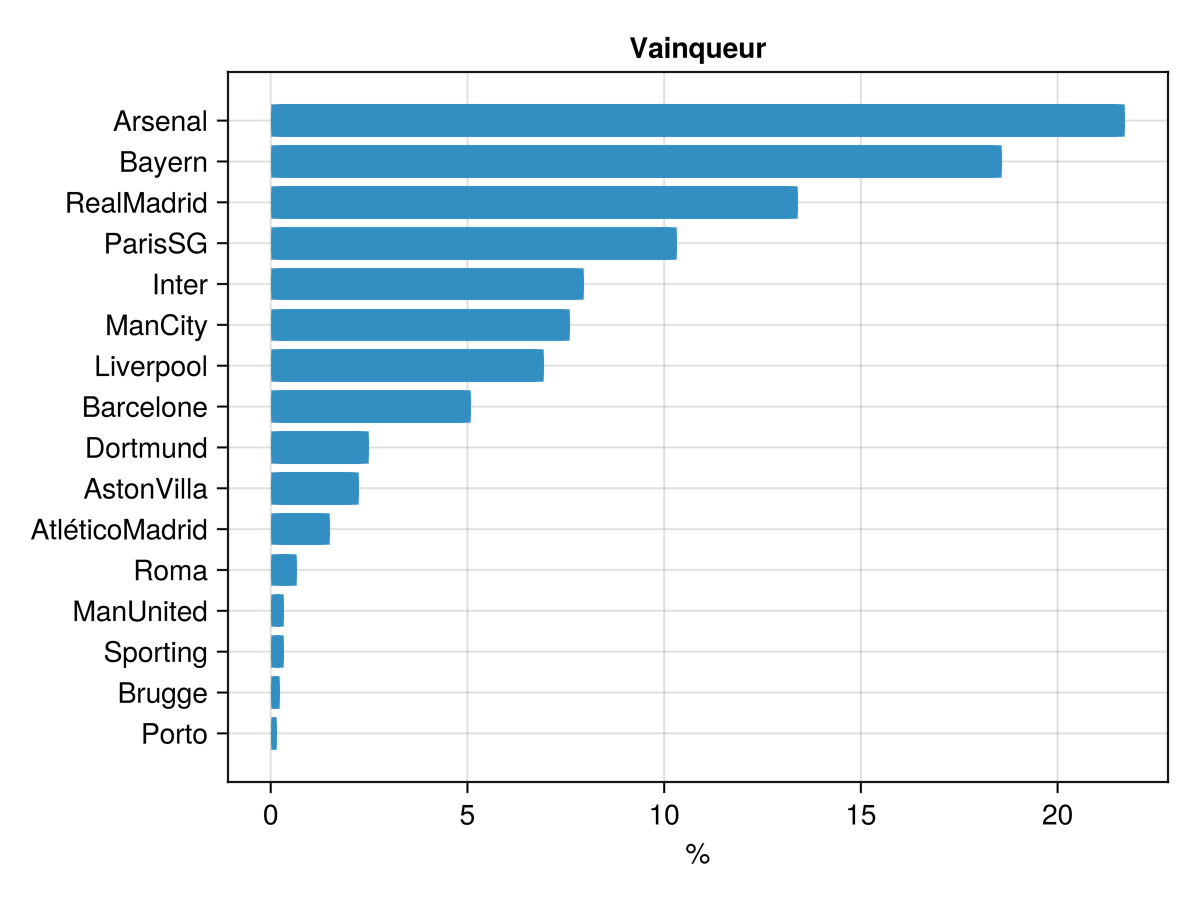

In [6]:
graphique_chances(df)

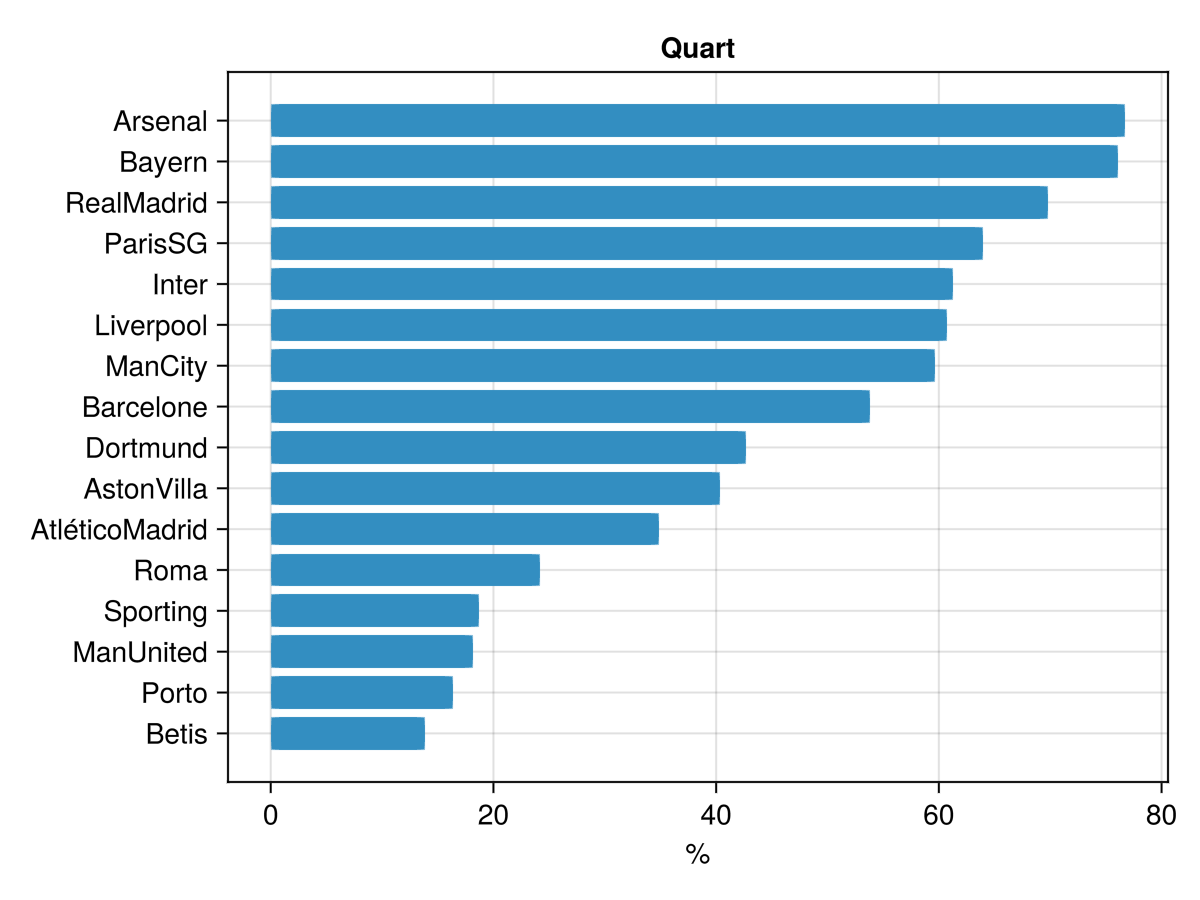

In [7]:
graphique_chances(df; etape = :Quart)

**Comment lire le tableau :**
- `xPoints` : le nombre moyen de points en phase de ligue
- `Top8`, `Top24`, `Elimine` : les chances (en %) de finir dans les 8 premiers, dans les 24 premiers (les 8 premiers sont compris), ou d'être éliminé dès la phase de ligue (`Elimine` = 100 − `Top24`)
- `Huitieme`, `Quart`, `Demie`, `Finale`, `Vainqueur` : les chances (en %) d'arriver à cette étape (pour `Huitieme`, les 8 premiers y sont déjà qualifiés, les autres doivent gagner leur barrage)

*(Si on relance, les chiffres peuvent un peu bouger selon le nombre de threads de Julia.)*

**Ce qu'on remarque :**

- **Il y a 4 favoris :** Arsenal (environ 22 %), le Bayern (18,6 %), le Real Madrid (13 %) et le PSG (10 %), soit environ 64 % des titres à eux quatre. Les 8 meilleurs clubs se partagent environ 92 % des titres, les 28 autres moins de 9 %.
- **Même le favori gagne moins d'une fois sur 4 :** avec les matchs à élimination directe, une mauvaise soirée suffit pour sortir.
- **Bizarrement, c'est le Bayern qui fait le plus de points en phase de ligue (17,6), mais c'est Arsenal qui gagne le plus souvent.** Une explication probable : leur force est presque la même (poids de 0,484 pour le Bayern et 0,507 pour Arsenal), mais le Bayern a un calendrier plus facile (le poids moyen de ses 8 adversaires est de −0,014, contre +0,051 pour Arsenal, calculé à partir de `matchs.csv`), d'où ses points en plus. Ensuite, en phase finale, Arsenal est un peu plus fort et meilleur aux tirs au but (82,9 % contre 77,7 % après lissage). On n'a pas mesuré la part de chaque effet : ce sont des explications probables, pas des preuves.
- **Finir dans le top 8 aide beaucoup**, parce qu'on évite le barrage. Les 8 meilleurs clubs y arrivent dans 53 à 80 % des cas.
- **En bas du tableau**, Sabah FC, le LASK et Viking sont éliminés dès la phase de ligue environ 9 fois sur 10 (92 %, 90 % et 89 %).
- Sur le graphique des quarts, les clubs sont plus proches : beaucoup arrivent souvent en quarts. C'est après que les favoris font la différence.

## 6. On compare les 4 modèles

On fait tourner les 4 modèles avec leurs paramètres par défaut. Chacun a son propre $\mu$ (voir le tableau de la section 3), réglé pour avoir à peu près 3 buts par match. Cette fonction n'utilise pas de `seed` : elle continue à partir du hasard des cellules précédentes. En relançant tout le notebook dans l’ordre, on retrouve les mêmes chiffres, mais en exécutant cette cellule seule, ils changent un peu (de l’ordre de 0,4 point).

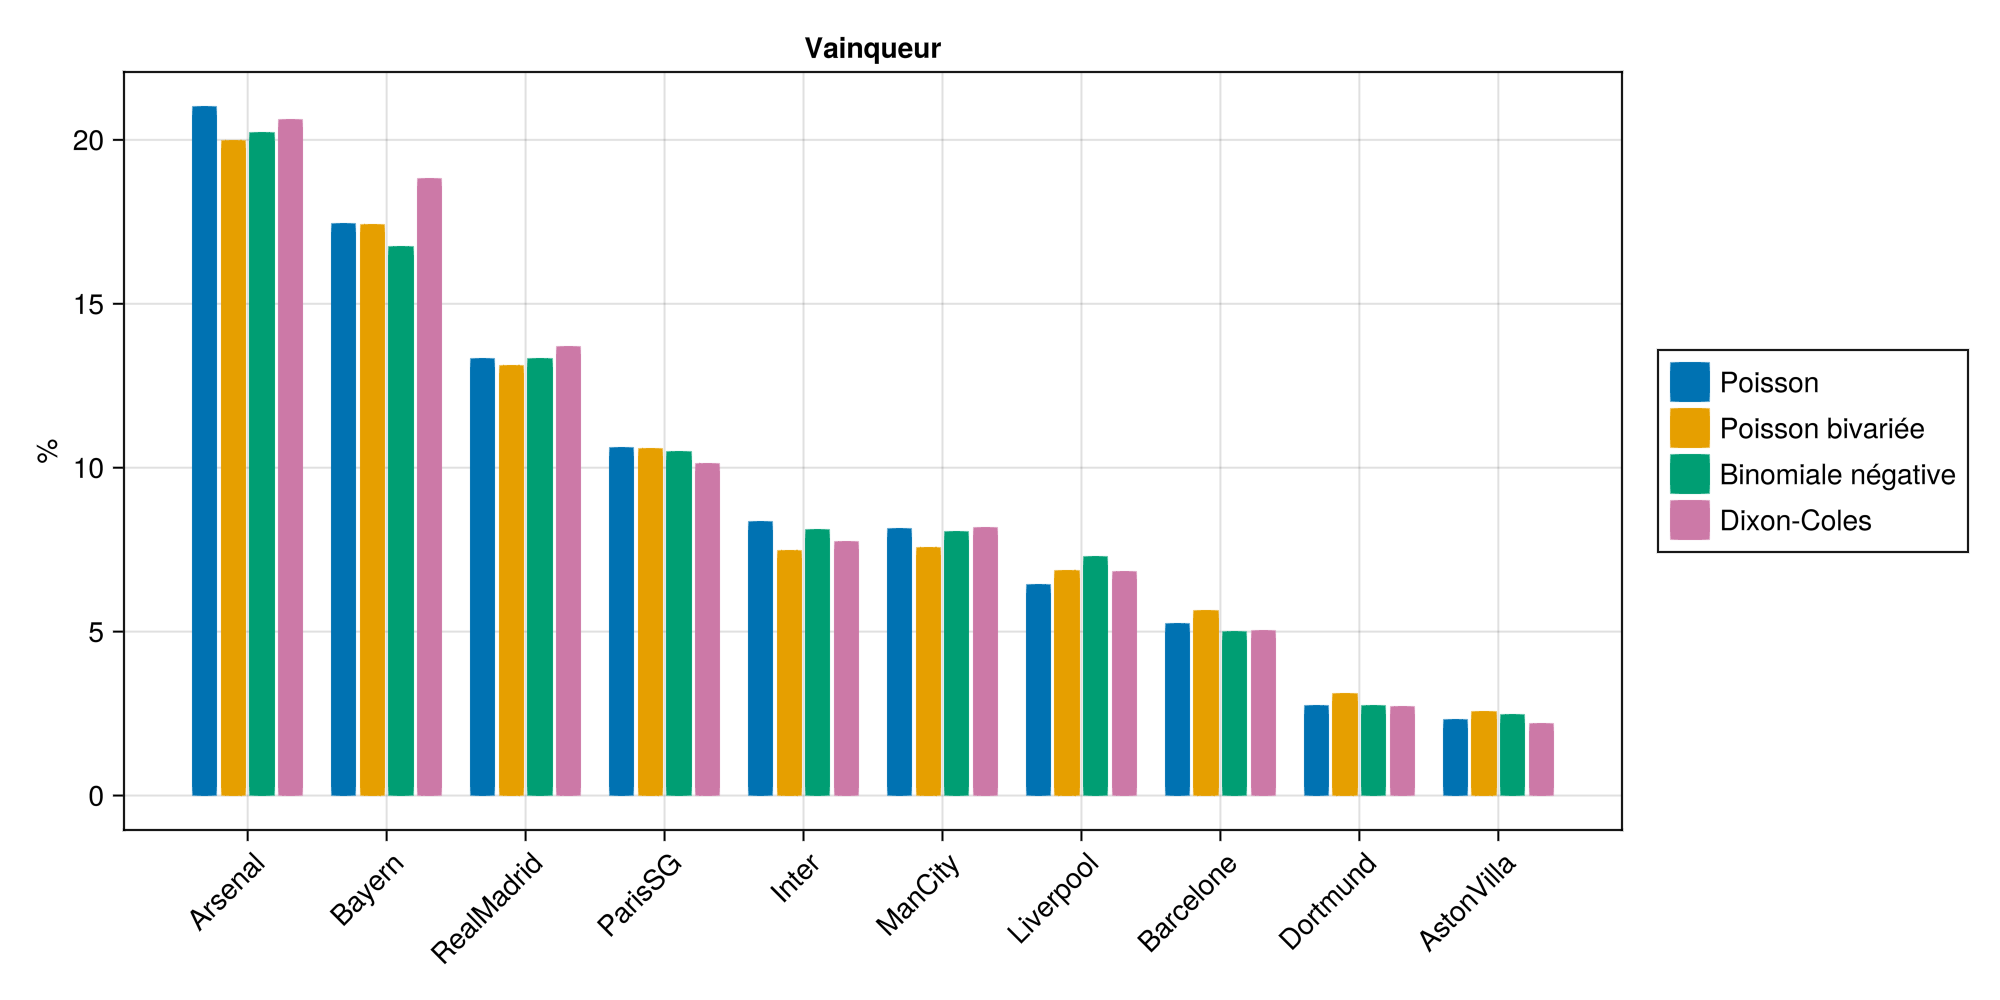

In [8]:
comparaison_modeles(N)

**Ce qu'on remarque (valeurs lues sur le graphique, donc approximatives) :**

- **Les 4 modèles donnent les mêmes 4 favoris, dans le même ordre** : Arsenal, Bayern, Real Madrid, PSG. Derrière, Inter, City et Liverpool sont très proches et leur ordre change un peu selon le modèle. Les différences entre modèles restent petites : environ 2 points au maximum (Arsenal entre 20 % et 21 %, Bayern entre 17 % et 19 %).
- **Poisson et Dixon-Coles sont proches** (Arsenal environ 21,0 % contre 20,6 %, Bayern environ 17,5 % contre 18,8 %). Les écarts ne vont pas dans le même sens pour les deux clubs, et ils sont du même ordre que la marge d'erreur due au hasard sur un écart entre deux simulations (environ ± 1 point). On ne détecte donc pas de différence nette entre les deux modèles. Cela s'explique sans doute par le fait que la correction de Dixon-Coles ne touche que 4 scores (0-0, 1-0, 0-1 et 1-1).
- Avec la **binomiale négative** et la **Poisson bivariée**, Arsenal gagne un peu moins souvent (environ 20 % contre 21 % pour Poisson). Pour le Bayern, c'est vrai avec la binomiale négative (environ 16,7 % contre 17,5 %), mais pas avec la Poisson bivariée. L'effet est donc faible et du même ordre que le hasard.
  - Binomiale négative : c'est logique, les scores varient plus, donc il y a plus de surprises.
  - Poisson bivariée : comme les buts communs ne changent pas l'écart de buts (voir section 3), ce modèle revient à une Poisson avec $\mu = 1$, donc moins de buts et plus de hasard. On retrouve d'ailleurs à peu près les chiffres de la section 7 pour $\mu = 1$ (Arsenal 20,6 %, Bayern 17,5 %). Ce modèle n'apporte donc rien de plus que de changer $\mu$.
- Donc **le choix du modèle ne change pas grand-chose** au résultat final.

## 7. Et si on change le nombre de buts ($\mu$) ?

Pour deux clubs de même force, $\mu = 1$, $1{,}25$ et $1{,}5$ donnent à peu près 2,2, 2,75 et 3,3 buts par match. On garde le modèle de Dixon-Coles et la même `seed`.

In [9]:
for μ in [1.0, 1.25, 1.5]
    d = classement_stats(rand(N, ModeleDixonColes(μ = μ); seed = 1))
    println("μ = $μ : ", first(sort(d, :Vainqueur, rev = true), 3)[:, [:Club, :Vainqueur]])
end

μ = 1.0 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         20.63
   2 │ Bayern          17.5
   3 │ RealMadrid      12.52
μ = 1.25 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         21.72
   2 │ Bayern          18.58
   3 │ RealMadrid      13.4
μ = 1.5 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         22.01
   2 │ Bayern          18.62
   3 │ RealMadrid      14.12


**Ce qu'on remarque :**

- Les 3 favoris restent les mêmes quel que soit $\mu$, dans le même ordre.
- Quand $\mu$ augmente, les trois favoris gagnent un peu plus souvent : Arsenal passe de 20,6 % à 21,7 % puis 22,0 %, le Bayern de 17,5 % à 18,6 % puis 18,6 %, le Real de 12,5 % à 13,4 % puis 14,1 %. Entre $\mu = 1$ et $\mu = 1{,}5$, la hausse est de 1 à 1,6 point, ce qui dépasse la marge d'erreur due au hasard. En revanche, entre $1{,}25$ et $1{,}5$, la hausse est très faible pour Arsenal (+0,3) et le Bayern (+0,04).
- Une explication possible : avec plus de buts, il y a moins de matchs nuls, donc moins de tirs au but (où tout peut arriver), et le résultat dépend moins du hasard. On ne l'a pas testé.
- Dans tous les cas l'effet est petit, donc ce n'est pas grave si $\mu$ n'est pas réglé parfaitement.

## 8. Est-ce que 10 000 simulations, c'est assez ?

In [10]:
for n in [1000, 10000, 50000]
    d = classement_stats(rand(n, ModeleDixonColes(); seed = 2))
    println("n = $n : ", first(sort(d, :Vainqueur, rev = true), 3)[:, [:Club, :Vainqueur]])
end

n = 1000 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal          20.1
   2 │ Bayern           17.6
   3 │ RealMadrid       14.6
n = 10000 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         21.0
   2 │ Bayern          17.78
   3 │ RealMadrid      13.96
n = 50000 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         21.46
   2 │ Bayern          18.11
   3 │ RealMadrid      13.44


On a relancé avec 1 000, 10 000 et 50 000 simulations pour comparer.

L'erreur faite en estimant une probabilité $p$ avec $n$ essais est d'environ $\sqrt{p(1-p)/n}$. Dans 95 % des cas, on est à moins de 2 fois cette erreur de la vraie valeur. Pour $p = 0{,}2$ :

| $n$ | erreur | marge à 95 % |
|---|---|---|
| 1 000 | environ 1,3 point | environ ± 2,5 points |
| 10 000 | environ 0,4 point | environ ± 0,8 point |
| 50 000 | environ 0,2 point | environ ± 0,35 point |

**Ce qu'on remarque :**

- On retrouve bien ça. Avec 1 000 simulations, les chiffres peuvent s'écarter de ceux à 50 000 simulations de plus d'un point (Arsenal 20,1 % contre 21,5 %, Real Madrid 14,6 % contre 13,4 %). Dans ce cas, l'écart entre le Bayern (17,6 %) et le Real Madrid (14,6 %) est à peine plus grand que la marge d'erreur : on ne serait pas sûr que le Bayern soit vraiment devant.
- Entre 10 000 et 50 000, les chiffres bougent peu, de l'ordre de l'erreur attendue (Arsenal 21,0 % puis 21,5 %, Bayern 17,8 % puis 18,1 %).
- **10 000 simulations suffisent pour classer les favoris** : l'erreur (0,4 point) est bien plus petite que les écarts entre eux.
- Mais pour des clubs très proches, ce n'est pas assez. Par exemple, dans la section 5, Inter (7,96 %) et Manchester City (7,60 %) ne sont séparés que de 0,36 point, alors que l'erreur sur cet écart est d'environ 0,4 point : on ne peut pas dire lequel est vraiment devant.

## 9. Conclusion

En simulant 10 000 fois la Ligue des champions, on a pu estimer les chances de chaque club à chaque étape. D'après nos simulations (modèle de Dixon-Coles), **Arsenal est le favori avec environ 22 % de chances**, devant le Bayern, le Real Madrid et le PSG.

- Les résultats sont **assez stables** : ils changent d'environ 2 points au maximum quand on change de modèle ou de nombre de buts, et 10 000 simulations donnent une précision de l'ordre de ±0,8 point.
- Même le favori gagne moins d'une fois sur 4 : en Ligue des champions, il y a beaucoup de hasard.
- Le Bayern fait plus de points qu'Arsenal en phase de ligue (probablement à cause d'un calendrier plus facile), mais Arsenal gagne plus souvent ensuite.

**Les limites de notre projet :**
- la force d'un club ne change pas pendant la compétition (pas de blessures, pas de forme du moment) ;
- la force vient seulement des coefficients UEFA, et la façon de la transformer en buts ($e^{\Delta}$ avec $\Delta$ entre $-1$ et $1$) est un choix qu'on n'a pas testé ;
- le tirage de la phase finale est simplifié : on ne tient compte ni du pays des clubs, ni d'autres règles du vrai tirage ;
- certains paramètres ($\mu$, $\rho$, l'avantage à domicile de 1,2) ont été choisis à la main, on ne les a pas calculés à partir de vrais matchs ;
- on n'a pas comparé nos résultats avec la réalité (saisons passées, cotes des bookmakers) : les pourcentages disent ce que donne notre modèle, pas ce qui va se passer ;
- chaque pourcentage a une marge d'erreur (environ ±0,8 point à 20 %), donc on ne peut pas classer deux clubs séparés de moins d'un point.